Dimensions de X :  (100, 2)
Dimensions de y :  (100, 1)


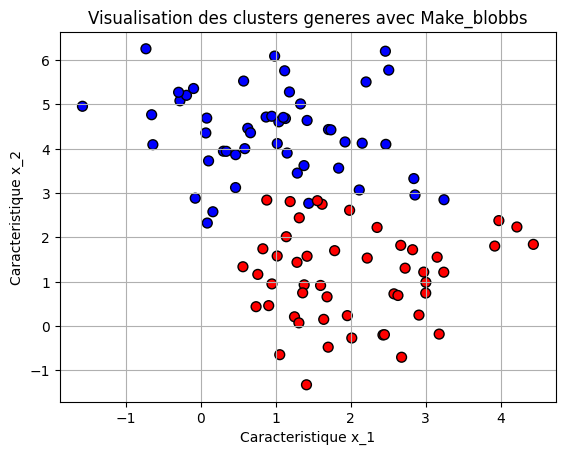

In [2]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

nb_obs=100
dim = 2
k=2
seed=0

X,y=make_blobs(n_samples=nb_obs , n_features=dim , centers=k , random_state=seed)

y=y.reshape((y.shape[0] , 1))

print('Dimensions de X : ' , X.shape)
print('Dimensions de y : ' , y.shape)

plt.scatter(X[:,0] , X[:,1], c=y , cmap="bwr" , edgecolors='k' , s=50)
plt.xlabel('Caracteristique x_1')
plt.ylabel('Caracteristique x_2')
plt.title("Visualisation des clusters generes avec Make_blobbs")
plt.grid(True)

In [3]:
def initialisation(X):
    return (np.random.randn(X.shape[1] , 1) 
            , np.random.randn(1))

In [4]:
def model(X , w , w0):
    m = X.dot(w) + w0
    return 1/(1+np.exp(-m))

In [5]:
def loss(A, y):
    return 1 / len(y) * np.sum(-y * np.log(A) - (1 - y) * np.log(1 - A))

In [6]:
def update(A, X, y, W, W0, taux):
    W = W - taux / len(y) * np.dot(X.T, A - y)
    W0 = W0 - taux / len(y) * np.sum(A - y)
    return (W, W0)

In [20]:
def prediction(W, W0, X):
    A = model(X, W, W0)
    return A >= .5


def perceptron(X, y, taux=0.1, n_iter=100):
    w, w0 = initialisation(X)
    loss_history = []
    for i in range(n_iter):
        A = model(X, w, w0)

        current_loss = loss(A, y)
        loss_history.append(current_loss)

        w, w0 = update(A, X, y, w, w0, taux)

        if (i + 1) % 100 == 0:
            print(f"iteration {i + 1} | loss : {current_loss}")

    return w, w0, loss_history


w, w0, loss_history = perceptron(X, y, taux=0.5, n_iter=1000)

iteration 100 | loss : 0.19975494436459781
iteration 200 | loss : 0.16234129811438947
iteration 300 | loss : 0.1434406779005438
iteration 400 | loss : 0.13238713495077092
iteration 500 | loss : 0.12519761881414992
iteration 600 | loss : 0.12016269824978
iteration 700 | loss : 0.1164455329959832
iteration 800 | loss : 0.11359156794642376
iteration 900 | loss : 0.11133344430527725
iteration 1000 | loss : 0.10950384543299359


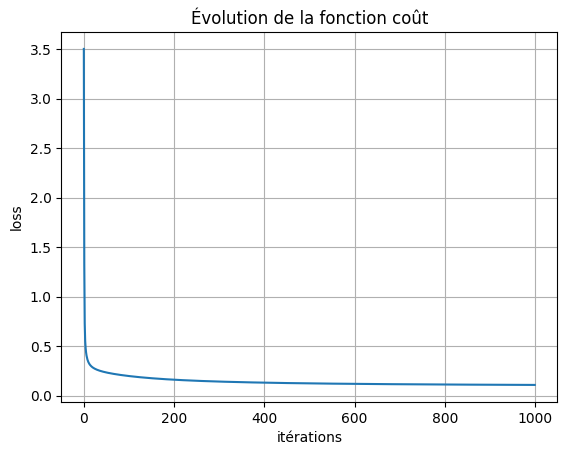

In [23]:
plt.plot(loss_history)
plt.xlabel("itérations")
plt.ylabel("loss")
plt.title("Évolution de la fonction coût")
plt.grid(True)
plt.show()

In [24]:
y_pred = prediction(w, w0, X)
score = np.mean(y_pred == y)

print("Score (accuracy) :", score)
print("Matrice de poids w :\n", w)
print("Biais w0 :", w0)

Score (accuracy) : 0.94
Matrice de poids w :
 [[ 0.69417197]
 [-2.85285488]]
Biais w0 : [6.54215529]


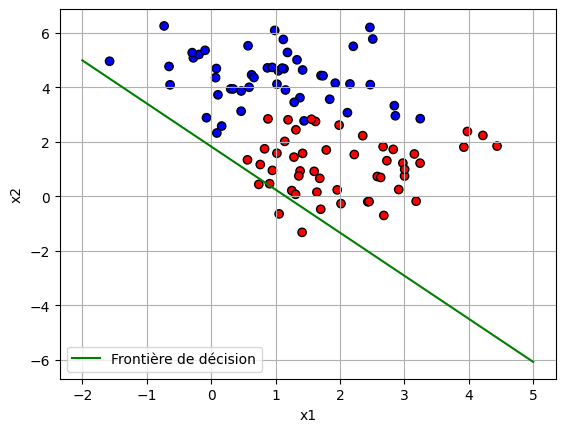

In [10]:
x1_vals = np.linspace(-2, 5, 100)
x2_vals = -(w[0, 0] * x1_vals + w0[0]) / w[1, 0]

plt.scatter(X[:,0],X[:,1], c=y, cmap='bwr', edgecolors='k')
plt.plot(x1_vals, x2_vals, 'g-', label="Frontière de décision")

plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()